In [3]:
import mrcfile
import torch

In [1]:
gaussian_stdev = 0.8
gaussian_amplitude = -1.0
distance = 4.0

In [6]:
boxsize = 16
volume = torch.zeros(boxsize, boxsize, boxsize) 

In [31]:
# Create a 3D Gaussian in volume
coords = torch.stack(torch.meshgrid(
        torch.arange(boxsize),
        torch.arange(boxsize),
        torch.arange(boxsize)
), dim=-1)
#.reshape(-1, 3) - torch.tensor([boxsize//2, boxsize//2, boxsize//2])
x_coords = coords[:,:,:, 2].float()
y_coords = coords[:,:,:, 1].float()
z_coords = coords[:,:,:, 0].float()
gaussian1 = gaussian_amplitude * torch.exp(-((x_coords - boxsize//2)**2 + (y_coords - boxsize//2)**2 + (z_coords - boxsize//2 + distance/2)**2) / (2 * gaussian_stdev**2))
gaussian2 = gaussian_amplitude * torch.exp(-((x_coords - boxsize//2)**2 + (y_coords - boxsize//2)**2 + (z_coords - boxsize//2 - distance/2)**2) / (2 * gaussian_stdev**2))

gaussian = gaussian1 + gaussian2

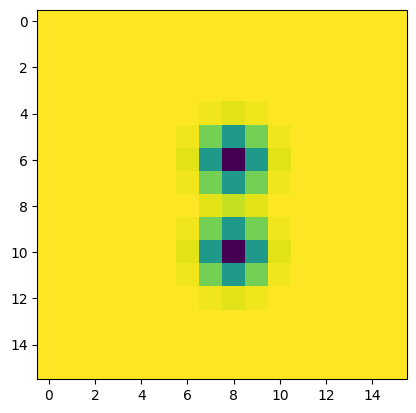

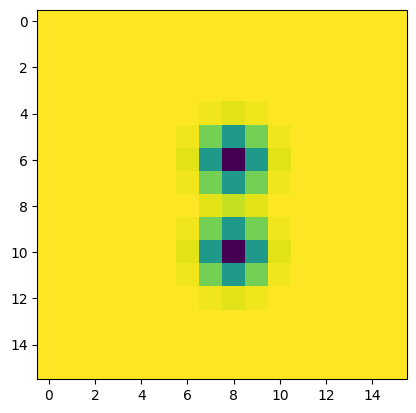

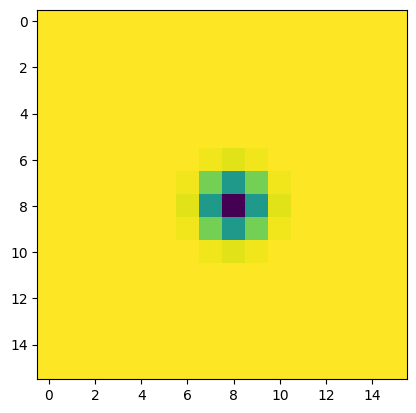

In [33]:
from matplotlib.pyplot import imshow, show

imshow(gaussian[:,:,boxsize//2])
show()
imshow(gaussian[:,boxsize//2,:])
show()
imshow(gaussian[boxsize//2,:,:])

In [35]:
mrcfile.write('dimer_gaussian.mrc', gaussian.numpy(), overwrite=True)